# Las otras calculadoras regulatorias: APR estandarizado de crédito, BA-CVA, sensibilidades FRTB y el piso de capital

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** el cuaderno 04 de este tema (SA-CCR)
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- buscar un ponderador de riesgo de crédito estandarizado y leer su párrafo, tabla y fecha de vigencia desde el `RegulatoryParameter` que lo lleva;
- calcular el capital del enfoque básico reducido de CVA (BA-CVA) desde una exposición en incumplimiento, y mostrar cómo la correlación entre contrapartes lo reduce;
- calcular el cargo delta GIRR del método basado en sensibilidades bajo los tres escenarios de correlación, con y sin la división de los ponderadores por $\sqrt{2}$;
- calcular la cascada de horizontes de liquidez de la pérdida esperada en cola y el piso de capital con su gradualidad y su tope;
- decir cuáles de estas calculadoras se verifican contra un ejemplo impreso y cuáles solo contra invariantes.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.8.1 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.regulatory import ba_cva, frtb, output_floor, standardised

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
matplotlib 3.11.2


## Datos

Dos documentos versionados alimentan este cuaderno.

- `data/derived/regulatory/calculators.json` (esquema `contraste.regulatory/v1`, estado de verdad `published-answer`): la grilla de 79 filas de ponderadores de riesgo de CRE20, la gradualidad del piso de capital, las tablas de ponderadores de BA-CVA y de horizontes de liquidez, los casos de invariantes (BA-CVA, el método basado en sensibilidades, la cascada de liquidez, el cargo GIRR) y los dos ejemplos del piso de capital.
- `data/derived/C12/single-swap.json`: el swap pagador a 10 años del cuaderno 01, cuyos bloques `ba_cva` y `girr` tienen un capital BA-CVA y un cargo delta GIRR calculados sobre su exposición SA-CCR y sus sensibilidades. El swap es sintético, la curva es la curva a la par del Tesoro de EE. UU. del 2025-09-30.

Qué se verifica contra un ejemplo impreso y qué no: los ponderadores de CRE20 y el piso de capital (RBC20.13) tienen valores impresos o tablas completas; **BA-CVA no tiene un ejemplo numérico oficial verificado** (adendum R8 de la investigación), así que sus pruebas se apoyan en invariantes y el documento lo dice; el cargo GIRR se apoya en los parámetros transcritos de MAR21 y en el invariante de que el cargo sin dividir es $\sqrt{2}$ veces el dividido.

La celda siguiente carga ambos documentos e imprime su identidad y la declaración de límite de BA-CVA.

In [2]:
# Cargar los dos documentos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio) e imprimir su identidad y límites
ROOT = Path("../../..").resolve()
doc = json.loads((ROOT / "data" / "derived" / "regulatory" / "calculators.json").read_text(encoding="utf-8"))
swap_doc = json.loads((ROOT / "data" / "derived" / "C12" / "single-swap.json").read_text(encoding="utf-8"))
swap = swap_doc["outputs"]

print("documento:", doc["document_id"], "| calculado con", doc["engine"]["version"], "| instalado", rv.__version__)
print("filas de la grilla CRE20:", len(doc["cre20_grid"]), "| casos de invariantes:", len(doc["invariant_cases"]), "| años de gradualidad:", len(doc["output_floor_phase_in"]))
print("tablas:", [t["id"] for t in doc["parameter_tables"]])
print("el documento de C12 marca su lectura de M en BA-CVA como no verificada:", "UNVERIF" in swap["ba_cva"]["limit"]["es"])

documento: regulatory-calculators-0.8.1 | calculado con 0.8.1 | instalado 0.8.1
filas de la grilla CRE20: 79 | casos de invariantes: 8 | años de gradualidad: 6
tablas: ['cre52-72-table-2', 'mar50-16-table-1', 'mar33-12-table-2', 'mar33-4-table-1']
el documento de C12 marca su lectura de M en BA-CVA como no verificada: True


## Método

### Paso 1: ponderadores estandarizados con su párrafo

Bajo el enfoque estandarizado de riesgo de crédito los activos ponderados por riesgo de una exposición son $EAD \times RW$, con $RW$ leído de una tabla por clase de exposición y tramo de calificación (CRE20). La dificultad no es la multiplicación sino la búsqueda: qué tabla, qué borde de un tramo de LTV, si la exposición es de corto plazo, qué marca lleva una empresa sin calificación. `lookup(exposure_class, key, **options)`, del motor, deriva a la función correcta y devuelve un `RegulatoryParameter`: el valor con su párrafo, su tabla y la fecha de vigencia de la versión del capítulo. Una clave fuera de la tabla se rechaza con un mensaje que nombra la tabla, nunca se responde con un valor de relleno. La celda siguiente busca algunos ponderadores y luego verifica las 79 filas de la grilla versionada.

In [3]:
# Buscar algunos ponderadores con su párrafo, verificar las 79 filas de la grilla versionada, y ver cómo se rechaza una clave fuera de la tabla
sample = [("sovereign", "A+ to A-", {}), ("bank-scra", "A", {"short_term": True}), ("bank-scra", "A", {}), ("corporate", "BBB+ to BBB-", {}),
          ("corporate", "sme-unrated", {}), ("retail", "transactor", {}), ("residential-re", "0.7", {}), ("equity", "speculative-unlisted", {}),
          ("defaulted", "provision-below-20pct", {})]
for cls, key, options in sample:
    p = standardised.lookup(cls, key, **options)
    print(f"{cls:15s}{key:24s}{str(options):22s} RW = {p.value:5.2f} | {p.paragraph:10s} | {p.table} | {p.in_force}")

same = 0
for row in doc["cre20_grid"]:
    p = standardised.lookup(row["exposure_class"], row["key"], short_term=row["short_term"], cash_flow_dependent=row["cash_flow_dependent"],
                            counterparty_weight=row["counterparty_weight"])
    same += (p.value, p.paragraph, p.table, p.in_force) == (row["risk_weight"], row["paragraph"], row["table"], row["in_force_date"])
print("filas de la grilla iguales al motor (ponderador, párrafo, tabla, fecha):", same, "de", len(doc["cre20_grid"]))

try:
    standardised.lookup("corporate", "AA")
except ValueError as err:
    print("una clave fuera de la tabla se rechaza con un ValueError que nombra la tabla CRE20 Table 10:", "CRE20 Table 10" in str(err))

book = [("empresa A", "corporate", "A+ to A-", 100.0), ("pyme sin calificación", "corporate", "sme-unrated", 40.0),
        ("hipotecario, LTV 70%", "residential-re", "0.7", 80.0), ("minorista transactor", "retail", "transactor", 20.0)]
total = 0.0
for name, cls, key, ead in book:
    rw = standardised.lookup(cls, key).value
    total += ead * rw
    print(f"{name:34s} EAD {ead:6.1f} x RW {rw:4.2f} = RWA {ead * rw:7.2f}")
print("APR total de la cartera pequeña:", total)

sovereign      A+ to A-                {}                     RW =  0.20 | CRE20.7    | CRE20 Table 1 | 2023-01-01
bank-scra      A                       {'short_term': True}   RW =  0.20 | CRE20.21   | CRE20 Table 7 | 2023-01-01
bank-scra      A                       {}                     RW =  0.40 | CRE20.21   | CRE20 Table 7 | 2023-01-01
corporate      BBB+ to BBB-            {}                     RW =  0.75 | CRE20.43   | CRE20 Table 10 | 2023-01-01
corporate      sme-unrated             {}                     RW =  0.85 | CRE20.47   | CRE20.47 | 2023-01-01
retail         transactor              {}                     RW =  0.45 | CRE20.68   | CRE20.68 | 2023-01-01
residential-re 0.7                     {}                     RW =  0.30 | CRE20.82   | CRE20 Table 11 | 2023-01-01
equity         speculative-unlisted    {}                     RW =  4.00 | CRE20.57   | CRE20.57 to CRE20.60 | 2023-01-01
defaulted      provision-below-20pct   {}                     RW =  1.50 | CRE20.

### Paso 2: el enfoque básico de capital por CVA

BA-CVA (MAR50.14 a MAR50.16) convierte la exposición en incumplimiento de cada contraparte en un capital por CVA sin simulación. Para la contraparte $c$ con conjuntos de neteo $NS$, vencimiento efectivo $M$ y exposición en incumplimiento $EAD$ (la de SA-CCR para un banco sin modelo interno):

$$SCVA_c = \frac{1}{\alpha}\,RW_c \sum_{NS} M_{NS}\,EAD_{NS}\,DF_{NS}, \quad DF = \frac{1 - e^{-0,05 M}}{0,05\,M}, \quad \alpha = 1,4$$

$$K_{reducido} = \sqrt{\Big(\rho \sum_c SCVA_c\Big)^2 + (1 - \rho^2) \sum_c SCVA_c^2}, \quad \rho = 50\%, \qquad \text{Capital} = DS \times K_{reducido},\ DS = 0,65$$

$RW_c$ viene de la Tabla 1 de MAR50.16 por sector y por grado de inversión o no. La celda siguiente recalcula el capital del swap único frente a una contraparte financiera de grado de inversión desde su exposición SA-CCR (cuaderno 04), y compara con el bloque versionado. El vencimiento $M$ es el vencimiento medio ponderado por nocional del conjunto de neteo; el documento marca esa lectura del párrafo como NO VERIFICADA, y nosotros también. Luego muestra cómo actúa $\rho$ con dos contrapartes iguales, y los dos invariantes del documento.

In [4]:
# Capital BA-CVA del swap único desde su exposición SA-CCR, el efecto de rho con dos contrapartes, y los dos invariantes del documento
cp = swap["ba_cva"]["counterparties"][0]
rw = ba_cva.sector_risk_weight(cp["sector"], True)
df = ba_cva.discount_factor(cp["m_years"], imm_bank=False)
scva = ba_cva.scva(rw.value, [(cp["m_years"], cp["ead"]["amount"])], imm_bank=False)
k_red = ba_cva.k_reduced([scva])
capital = ba_cva.capital(k_red)
print("sector y clase:", cp["sector"], cp["rating_class"], "| RW =", rw.value, "|", rw.paragraph, rw.table)
print("EAD (SA-CCR, sa_ccr.ead versionado):", round(cp["ead"]["amount"], 2), "| M =", cp["m_years"], "| DF =", round(df, 6))
print("SCVA:", round(scva, 2), "| K_reduced:", round(k_red, 2), "| capital = 0.65 K:", round(capital, 2))
print("brecha con el SCVA y el capital versionados:", abs(scva - cp["scva"]), abs(capital - swap["ba_cva"]["capital"]["amount"]))
print("capital como parte de la exposición en incumplimiento:", round(capital / cp["ead"]["amount"], 4))

for rho in (0.0, 0.5, 1.0):
    print(f"rho = {rho:3.1f} | K_reduced de dos contrapartes con SCVA 100:", round(ba_cva.k_reduced([100.0, 100.0], rho), 4))
for case in doc["invariant_cases"]:
    if case["calculator"] == "ba-cva":
        print(case["id"], "| se cumple en el documento:", case["holds"], "|", case["statement"]["es"])
print("K_full sin coberturas, beta 0.25, K_reduced 30:", ba_cva.k_full(30.0, 0.0, 0.25), "| el umbral de materialidad aplica en EUR 100 mil millones:", ba_cva.materiality_threshold_applies(1e11))

sector y clase: financials investment-grade | RW = 0.05 | MAR50.16 MAR50.16 Table 1
EAD (SA-CCR, sa_ccr.ead versionado): 528459.73 | M = 10.0 | DF = 0.786939
SCVA: 148523.36 | K_reduced: 148523.36 | capital = 0.65 K: 96540.18
brecha con el SCVA y el capital versionados: 0.0 0.0
capital como parte de la exposición en incumplimiento: 0.1827
rho = 0.0 | K_reduced de dos contrapartes con SCVA 100: 141.4214
rho = 0.5 | K_reduced de dos contrapartes con SCVA 100: 158.1139
rho = 1.0 | K_reduced de dos contrapartes con SCVA 100: 200.0
ba-cva-rho-one | se cumple en el documento: True | Con rho = 1 la base K_reduced es igual a la suma de los SCVA.
ba-cva-hedges-floor | se cumple en el documento: True | K_full = beta K_reduced + (1 - beta) K_hedged es al menos beta K_reduced.
K_full sin coberturas, beta 0.25, K_reduced 30: 7.5 | el umbral de materialidad aplica en EUR 100 mil millones: True


### Paso 3: el método basado en sensibilidades, delta GIRR

Para el riesgo de tasa de interés de la cartera de negociación, el método basado en sensibilidades (MAR21) pondera la sensibilidad $s_k$ de la posición a cada uno de los diez plazos por un ponderador, $WS_k = RW_k\,s_k$, y agrega dentro de un tramo de moneda con las correlaciones entre plazos:

$$K_b = \sqrt{\max\Big(0,\ \sum_k WS_k^2 + \sum_{k \ne l} \rho_{kl}\,WS_k\,WS_l\Big)}$$

La sensibilidad es $s_k = (V(r + 0,0001) - V(r))/0,0001$, el cambio de valor por un desplazamiento de un punto base **dividido por 0,0001**, no el PV01. El capital es el máximo de $K_b$ sobre tres escenarios de correlación (MAR21.6): el medio es $\rho$, el alto es $\min(1,25\rho, 1)$ y el bajo es $\max(2\rho - 1, 0,75\rho)$. Para una moneda especificada como el USD el banco puede dividir los ponderadores por $\sqrt{2}$ (MAR21.44); el documento lo trata como un parámetro con nombre con la etiqueta `convention` y escribe el cargo sin dividir junto al dividido. La celda siguiente lee las diez sensibilidades del swap único, calcula el cargo de ambas formas y compara con el bloque versionado.

In [5]:
# Cargo delta GIRR del swap único con y sin la división por raíz de 2, los tres escenarios, contra el bloque versionado
div, und = frtb.girr_parameters(True), frtb.girr_parameters(False)
s = np.array(swap["girr"]["sensitivities"])
head, beside = frtb.girr_delta_charge(s, div.tenors, div), frtb.girr_delta_charge(s, und.tenors, und)

print(f"{'plazo':>7s}{'s_k':>16s}{'RW %':>8s}{'RW/sqrt2 %':>12s}{'WS':>14s}")
for t, sk, a1, a2, ws in zip(div.tenors, s, und.risk_weights, div.risk_weights, head.weighted):
    print(f"{t:7.2f}{sk:16.1f}{a1 * 100:8.2f}{a2 * 100:12.3f}{ws:14.1f}")
print("K_b bajo / medio / alto:", [round(k, 2) for k in head.k_by_scenario], "| cargo = máximo:", round(head.charge, 2))
print("cargo versionado y cargo sin dividir:", round(swap["girr"]["delta_charge"]["amount"], 2), round(swap["girr"]["delta_charge_undivided"]["amount"], 2))
print("brecha del cargo dividido con el versionado:", abs(head.charge - swap["girr"]["delta_charge"]["amount"]), "| sin dividir / dividido:", round(beside.charge / head.charge, 6), "| sqrt(2) =", round(frtb.SQRT2, 6))
print("parte del cargo del plazo de 10 años:", round(abs(head.weighted[6]) / head.charge, 3))

  plazo             s_k    RW %  RW/sqrt2 %            WS
   0.25             0.0    1.70       1.202           0.0
   0.50        103024.5    1.70       1.202        1238.4
   1.00        351675.5    1.60       1.131        3978.8
   2.00        780319.5    1.30       0.919        7173.0
   3.00       1854805.6    1.20       0.849       15738.5
   5.00       6905676.2    1.10       0.778       53713.6
  10.00      72734182.1    1.10       0.778      565739.2
  15.00             0.0    1.10       0.778           0.0
  20.00             0.0    1.10       0.778           0.0
  30.00             0.0    1.10       0.778           0.0
K_b bajo / medio / alto: [639060.91, 643092.67, 647099.31] | cargo = máximo: 647099.31
cargo versionado y cargo sin dividir: 647099.31 915136.62
brecha del cargo dividido con el versionado: 0.0 | sin dividir / dividido: 1.414214 | sqrt(2) = 1.414214
parte del cargo del plazo de 10 años: 0.874


Dos casos del documento muestran la regla de agregación en acción. En el primero, dos tramos del mismo signo se agregan entre tramos con $\gamma = 0,5$ bajo los tres escenarios y el resultado SBM es el mayor. En el segundo, dos tramos de signo opuesto y $\gamma = 0,8$ hacen negativo el radicando bajo los escenarios medio y alto, y MAR21.4(5)(b) reemplaza $S_b$ por $\max(\min(\sum WS, K_b), -K_b)$; el motor informa si se usó la regla alternativa. La cascada de horizontes de liquidez de la pérdida esperada en cola (MAR33.4) suma la pérdida de los factores con horizontes más largos:

$$ES = \sqrt{ES_T(P)^2 + \sum_{j \ge 2} \Big(ES_T(P, j)\sqrt{\tfrac{LH_j - LH_{j-1}}{T}}\Big)^2}$$

La celda siguiente corre los dos casos de agregación y la cascada del documento desde sus entradas.

In [6]:
# Correr los dos casos de agregación SBM y la cascada de liquidez del documento desde sus entradas y compararlos con sus salidas versionadas
cases = {c["id"]: c for c in doc["invariant_cases"]}
print("correlaciones por escenario para rho = 0.5 (bajo, medio, alto):", [float(frtb.scenario_correlation(np.array(0.5), sc)) for sc in frtb.SCENARIOS])
for ident in ("sbm-bucket-and-cross-bucket-aggregation", "sbm-cross-bucket-fallback"):
    ins = {i["name"]: i["value"] for i in cases[ident]["inputs"]}
    outs = {o["name"]: o["value"] for o in cases[ident]["outputs"]}
    ws = [np.array(ins[k]) for k in sorted(ins) if k.startswith("ws_")]
    rho = [np.array(ins[f"rho_{b + 1}"]).reshape(len(w), len(w)) for b, w in enumerate(ws)]
    gamma = np.full((2, 2), ins["gamma"])
    np.fill_diagonal(gamma, 1.0)
    cross = {}
    print(ident)
    for sc in frtb.SCENARIOS:
        k_b = np.array([frtb.bucket_charge(w, r_, sc) for w, r_ in zip(ws, rho)])
        detail = frtb.cross_bucket_charge_detail(k_b, np.array([w.sum() for w in ws]), gamma, sc)
        cross[sc] = detail.charge
        print(f"  {sc:6s} K_b = {np.round(k_b, 4)} | entre tramos {detail.charge:9.4f} | alternativa usada: {detail.fallback_used} | versionado {outs['cross_bucket_' + sc]:.4f}")
    zero = {sc: 0.0 for sc in frtb.SCENARIOS}
    sbm = frtb.sbm_capital(cross, zero, zero)
    print("  SBM:", round(sbm.capital, 6), "escenario", sbm.scenario, "| versionado", round(outs["sbm_charge"], 6))

ins = {i["name"]: i["value"] for i in cases["cascade-two-horizons"]["inputs"]}
es = frtb.liquidity_cascade_es(ins["es_t_p"], {int(ins["lh_2"]): ins["es_t_p_2"]}, int(ins["t"]))
print("ES de la cascada:", round(es, 6), "| versionado", round(cases["cascade-two-horizons"]["outputs"][0]["value"], 6), "| al menos el ES base:", es >= ins["es_t_p"])
print("la cascada con todos los horizontes iguales a 10 devuelve el ES base:", frtb.liquidity_cascade_es(10.0, {}, 10))

correlaciones por escenario para rho = 0.5 (bajo, medio, alto): [0.375, 0.5, 0.625]
sbm-bucket-and-cross-bucket-aggregation
  low    K_b = [11.0454  6.7268] | entre tramos   15.4677 | alternativa usada: False | versionado 15.4677
  medium K_b = [10.583  7.   ] | entre tramos   16.0312 | alternativa usada: False | versionado 16.0312
  high   K_b = [10.0995  7.2629] | entre tramos   16.5756 | alternativa usada: False | versionado 16.5756
  SBM: 16.575584 escenario high | versionado 16.575584
sbm-cross-bucket-fallback
  low    K_b = [16.5831 16.5831] | entre tramos    8.3666 | alternativa usada: False | versionado 8.3666
  medium K_b = [17.3205 17.3205] | entre tramos   10.9545 | alternativa usada: True | versionado 10.9545
  high   K_b = [18.0278 18.0278] | entre tramos    0.0000 | alternativa usada: True | versionado 0.0000
  SBM: 10.954451 escenario medium | versionado 10.954451
ES de la cascada: 11.661904 | versionado 11.661904 | al menos el ES base: True
la cascada con todos los hori

### Paso 4: el piso de capital

El piso de capital limita cuánto pueden reducir el capital los modelos internos: los activos ponderados por riesgo son

$$APR = \max\big(APR_{nominado},\ f_t \times APR_{solo\text{-}SA}\big)$$

donde $APR_{solo\text{-}SA}$ se calcula solo con los enfoques estandarizados (RBC20.11 a RBC20.12) y $f_t$ sube cada año de 50% en 2023 a 72,5% desde 2028 (RBC90.1 Tabla 1). Durante la gradualidad un tope nacional puede limitar el aumento causado por el piso a 25% de los APR previos al piso (RBC90.2). `phase_in_factor` y `floored_rwa`, del motor, son dos funciones pequeñas; el valor de la verificación está en el ejemplo documentado (RBC20.13): APR nominado 76, solo estandarizado 140, factor 72,5%, que da 101,5, y 95 con el tope. La celda siguiente evalúa el ejemplo, la gradualidad año a año y el tope, y dibuja el APR con piso por año.

rbc20-13-output-floor          resultado 101.500 | impreso 101.5 | versionado 101.5
rbc20-13-output-floor-capped   resultado  95.000 | impreso 95 | versionado 95.0
   año    f_t    APR con piso    con tope 25%  activo
  2023  0.500           76.00           76.00  False
  2024  0.550           77.00           77.00  True
  2025  0.600           84.00           84.00  True
  2026  0.650           91.00           91.00  True
  2027  0.700           98.00           95.00  True
  2028  0.725          101.50           95.00  True
primer año en que el piso es activo: 2024
un año anterior a 2023 se rechaza con un ValueError que nombra RBC90.1: True


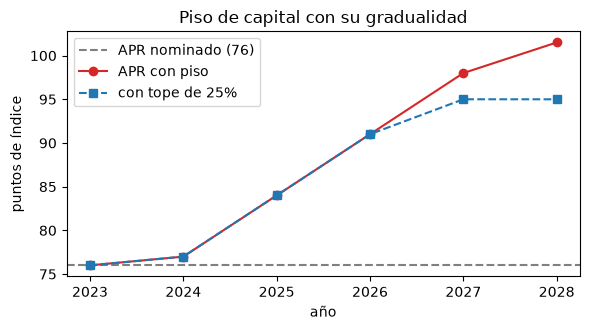

In [7]:
# Evaluar el ejemplo documentado, la gradualidad año a año con el tope, y comparar con la tabla de gradualidad versionada
floor_examples = {e["id"]: e for e in doc["official_examples"] if e["calculator"] == "output-floor"}
for ident, e in floor_examples.items():
    ins = {i["name"]: i["value"] for i in e["inputs"]}
    value = output_floor.floored_rwa(ins["rwa_nominated"], ins["rwa_sa_only"], ins["floor_factor"], ins.get("cap_share"))
    print(f"{ident:30s} resultado {value:7.3f} | impreso {e['published'][0]['value']} | versionado {e['outputs'][0]['value']}")

nominated, sa_only = 76.0, 140.0
years = list(range(2023, 2029))
rows = []
for year in years:
    f = output_floor.phase_in_factor(year)
    rows.append((year, f.value, output_floor.floored_rwa(nominated, sa_only, f.value), output_floor.floored_rwa(nominated, sa_only, f.value, 0.25)))
    committed = next(r for r in doc["output_floor_phase_in"] if r["year"] == year)
    assert (f.value, f.paragraph, f.table) == (committed["factor"], committed["paragraph"], committed["table"])
print(f"{'año':>6s}{'f_t':>7s}{'APR con piso':>16s}{'con tope 25%':>16s}  activo")
for year, f, floored, capped in rows:
    print(f"{year:6d}{f:7.3f}{floored:16.2f}{capped:16.2f}  {floored > nominated}")
print("primer año en que el piso es activo:", next(y for y, _, fl, _c in rows if fl > nominated))
try:
    output_floor.phase_in_factor(2022)
except ValueError as err:
    print("un año anterior a 2023 se rechaza con un ValueError que nombra RBC90.1:", "RBC90.1" in str(err))

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.axhline(nominated, color="grey", ls="--", label="APR nominado (76)")
ax.plot(years, [r_[2] for r_ in rows], "o-", color="tab:red", label="APR con piso")
ax.plot(years, [r_[3] for r_ in rows], "s--", color="tab:blue", label="con tope de 25%")
ax.set_xlabel("año")
ax.set_ylabel("puntos de índice")
ax.set_title("Piso de capital con su gradualidad")
ax.legend()
fig.tight_layout()
plt.show()

## Resultados

- **Ponderadores de riesgo.** Un soberano con calificación A+ a A- pondera 20%, un banco de grado SCRA A 40% (20% si es de corto plazo), una empresa calificada BBB 75%, una pyme sin calificación 85%, un transactor 45%, un hipotecario con LTV de 70% 30%, renta variable especulativa no listada 400%, y una exposición en incumplimiento con provisión bajo 20% 150%. Cada uno viene con su párrafo, tabla y fecha de vigencia. Las 79 filas de la grilla versionada son iguales a la búsqueda del motor en ponderador, párrafo, tabla y fecha, y una clave fuera de la tabla (una calificación corporativa "AA") se rechaza con el nombre de la tabla. La cartera pequeña de cuatro exposiciones tiene APR 117,0.
- **BA-CVA.** Para el swap único, con una exposición en incumplimiento de 528.459,73 USD de SA-CCR, una contraparte financiera de grado de inversión (ponderador 5%) y un vencimiento de 10 años (factor de descuento 0,7869), SCVA es 148.523,36 y el capital es $0,65 \times K_{reducido} = 96.540,18$ USD, 18,3% de la exposición en incumplimiento; ambos son iguales al bloque versionado. Con dos contrapartes de SCVA 100 cada una, $K_{reducido}$ es 141,42 con $\rho=0$, 158,11 con $\rho=0,5$ y 200 con $\rho=1$, la suma simple: cuanto menos se mueven juntas las contrapartes, menor es el capital, 21% con $\rho=0,5$ y 29% con $\rho=0$ respecto de la suma. Los dos invariantes se cumplen, y $K_{full}$ sin coberturas es $\beta K_{reducido} = 7,5$. No hay un ejemplo oficial verificado, así que son verificaciones de estructura, no de un número publicado.
- **Delta GIRR.** El plazo de 10 años lleva 87,4% del cargo, porque el swap es largo y su sensibilidad se concentra allí. El escenario medio da $K_b$ = 643.092,67, el bajo 639.060,91 y el alto 647.099,31, que es el cargo (igual al versionado). Dividir los ponderadores por $\sqrt{2}$ da 647.099,31 y no dividirlos da 915.136,62, una razón de 1,414214: el cargo es homogéneo de grado uno en los ponderadores, así que la división es una elección de escala que el banco hace a su discreción, y el documento muestra ambos.
- **Agregación.** En el caso de dos tramos el escenario de correlación alta da el mayor cargo, 16,5756. En el caso de signos opuestos con $\gamma=0,8$ el escenario bajo aplica la fórmula simple (8,3666) mientras que el medio y el alto recurren a $\max(\min(\sum WS, K_b), -K_b)$, y el motor lo informa; el cargo es el valor medio, 10,9545. La cascada de liquidez con un segundo horizonte da 11,6619 desde una base de 10, y devuelve la base cuando todos los horizontes son 10.
- **Piso de capital.** El ejemplo da 101,5, y 95 con el tope, como se imprime. Con APR nominado 76 y APR estandarizado 140 el piso se activa por primera vez en 2024 (77 contra 76), llega a 101,5 en 2028, y el tope de 25% mantiene el resultado en 95 desde 2027.

Lo que este cuaderno no muestra: los ponderadores estandarizados son las tablas transcritas del motor, y asignar una calificación a un tramo (CRE21) es de quien llama; los términos completos de cobertura de BA-CVA, SA-CVA, vega, curvatura, las otras clases de riesgo del método basado en sensibilidades, el cargo por riesgo de incumplimiento y el recargo por riesgo residual no están implementados.

## Resumen

- Un ponderador de riesgo estandarizado es un `RegulatoryParameter`: un valor con su párrafo, tabla y fecha de vigencia, encontrado por `lookup`, y rechazado con el nombre de la tabla cuando la clave no está en ella.
- El capital BA-CVA es $0,65\sqrt{(\rho\sum SCVA)^2 + (1-\rho^2)\sum SCVA^2}$ con $SCVA$ desde la exposición en incumplimiento; no tiene un ejemplo oficial verificado, y el cuaderno dice en qué se apoya.
- El cargo delta GIRR es el máximo sobre tres escenarios de correlación de la agregación de $RW_k s_k$; dividir los ponderadores por $\sqrt{2}$ escala el cargo exactamente por $1/\sqrt{2}$.
- El piso de capital es $\max(\text{nominado}, f_t \times \text{estandarizado})$ con $f_t$ de 50% a 72,5%; el ejemplo documentado da 101,5 y 95 con el tope.

**Qué probar después.** Cambia el sector de la contraparte a `technology-telecoms` o su calidad crediticia a alto rendimiento y mira el capital BA-CVA; usa `lookup` con una exposición inmobiliaria comercial con y sin ponderador de contraparte. Luego sigue con el cuaderno 06.

## Referencias

- BCBS, Basel Framework, CRE20 Standardised approach: individual exposures (in force 2023-01-01, published 2025-06-10). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/20/inforce/2023-01-01/published/2025-06-10
- BCBS, Basel Framework, MAR50 CVA risk framework (in force 2023-01-01, published 2020-07-08). https://www.bis.org/committees/bcbs/basel-framework/standard/mar/50/inforce/2023-01-01/published/2020-07-08
- BCBS, Basel Framework, MAR21 Standardised approach: sensitivities-based method (in force 2023-01-01). https://www.bis.org/committees/bcbs/basel-framework/standard/mar/21/inforce/2023-01-01/published/2026-03-23
- BCBS, Basel Framework, RBC20 Calculation of minimum risk-based capital requirements (in force 2023-01-01, published 2020-11-26). https://www.bis.org/committees/bcbs/basel-framework/standard/rbc/20/inforce/2023-01-01/published/2020-11-26
- BCBS, Basel Framework, RBC90 Transitional arrangements and the output floor phase-in (in force 2023-01-01). https://www.bis.org/committees/bcbs/basel-framework/standard/rbc/90/inforce/2023-01-01/published/2020-03-27
- BCBS, Basel Framework, CRE52 Standardised approach to counterparty credit risk (in force 2023-01-01, published 2020-06-05). https://www.bis.org/committees/bcbs/basel-framework/standard/cre/52/inforce/2023-01-01/published/2020-06-05